# Ejemplos completos de la clase 1
El mismo programa está incluido en el anexo del Word Tema. Todos los datos se generan aquí o se cargan desde los conjuntos incorporados en scikit-learn. Las cuatro figuras se guardan en Figuras. Fuente del código: elaboración propia para el curso.

Wine: varianza acumulada en 2 componentes 0.5541


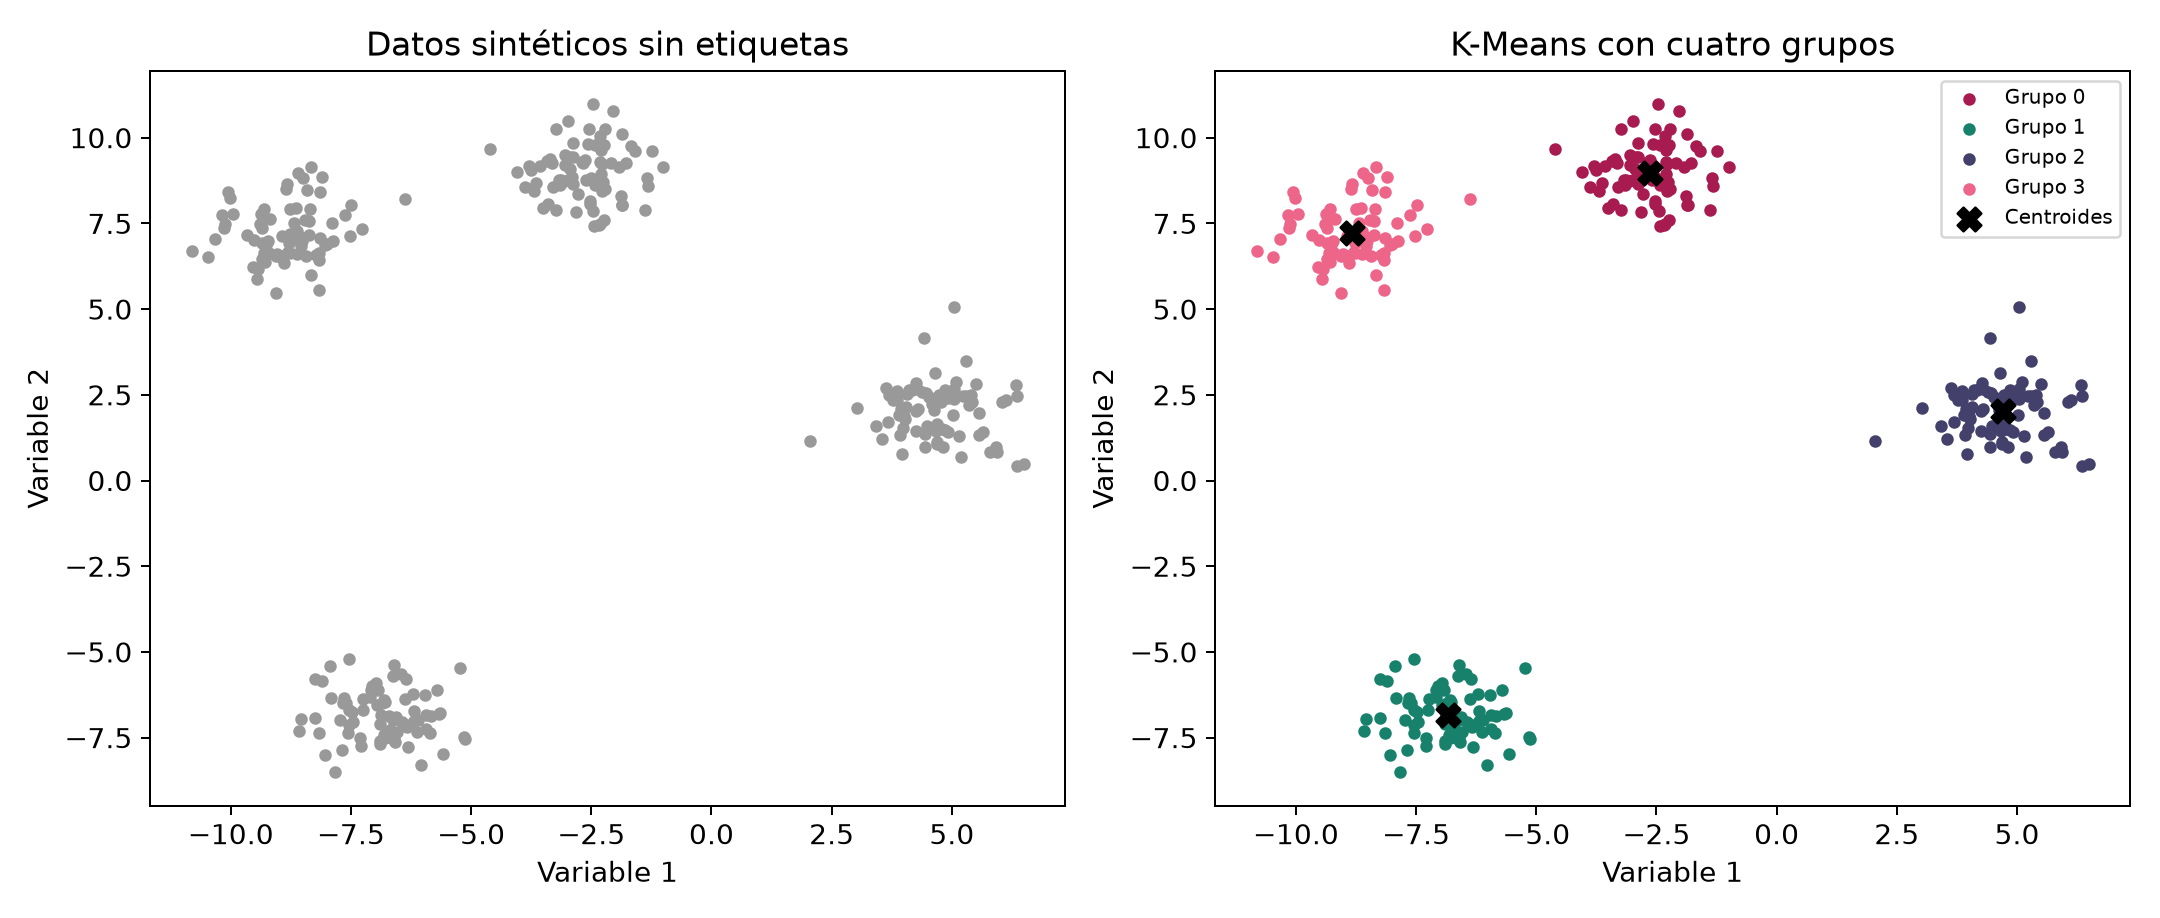

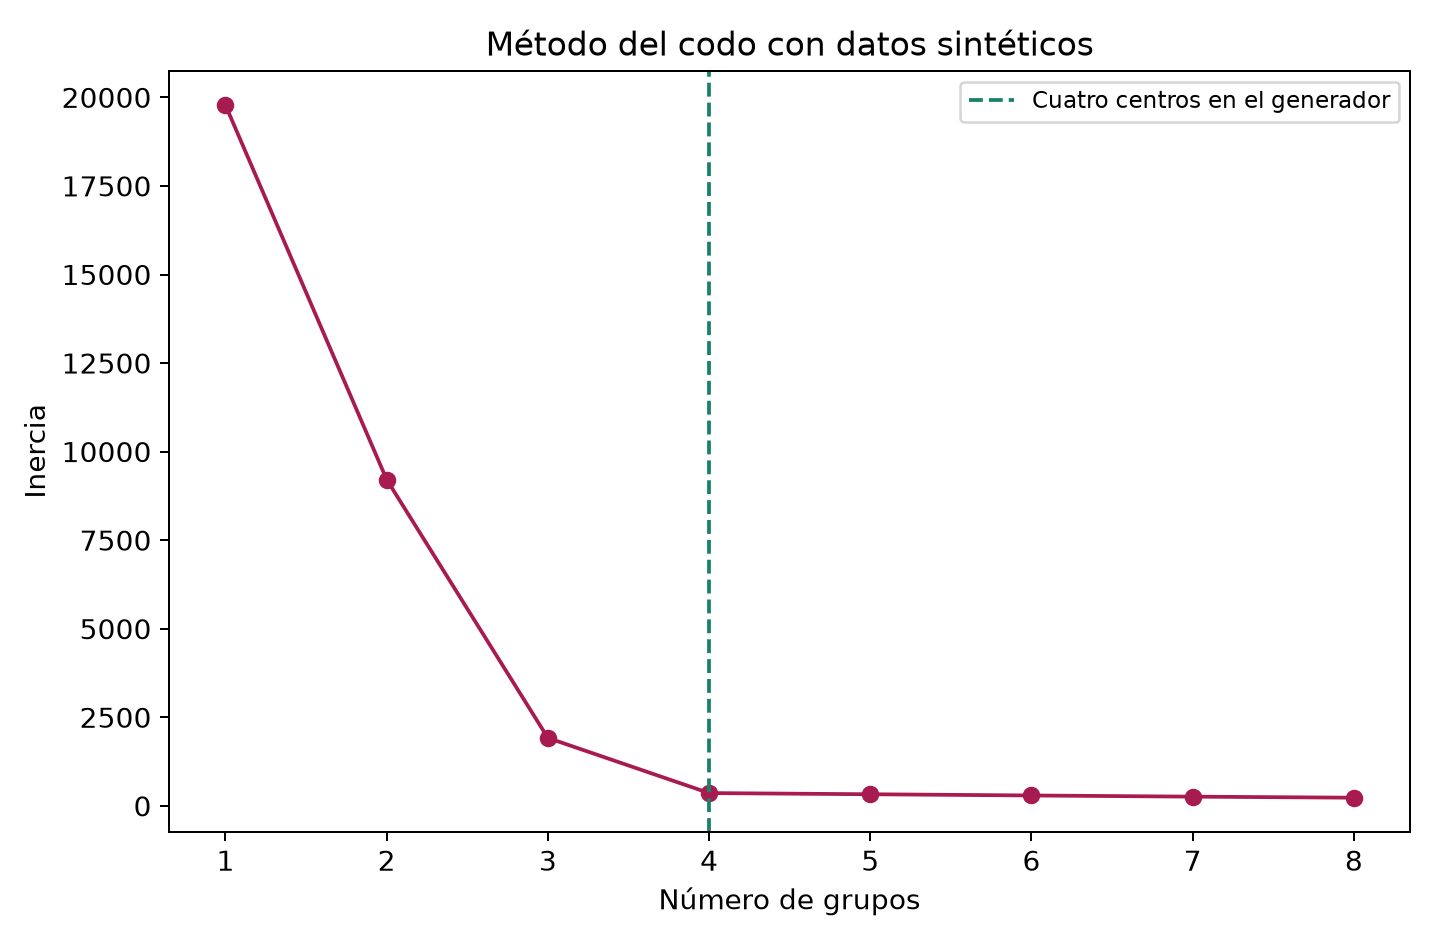

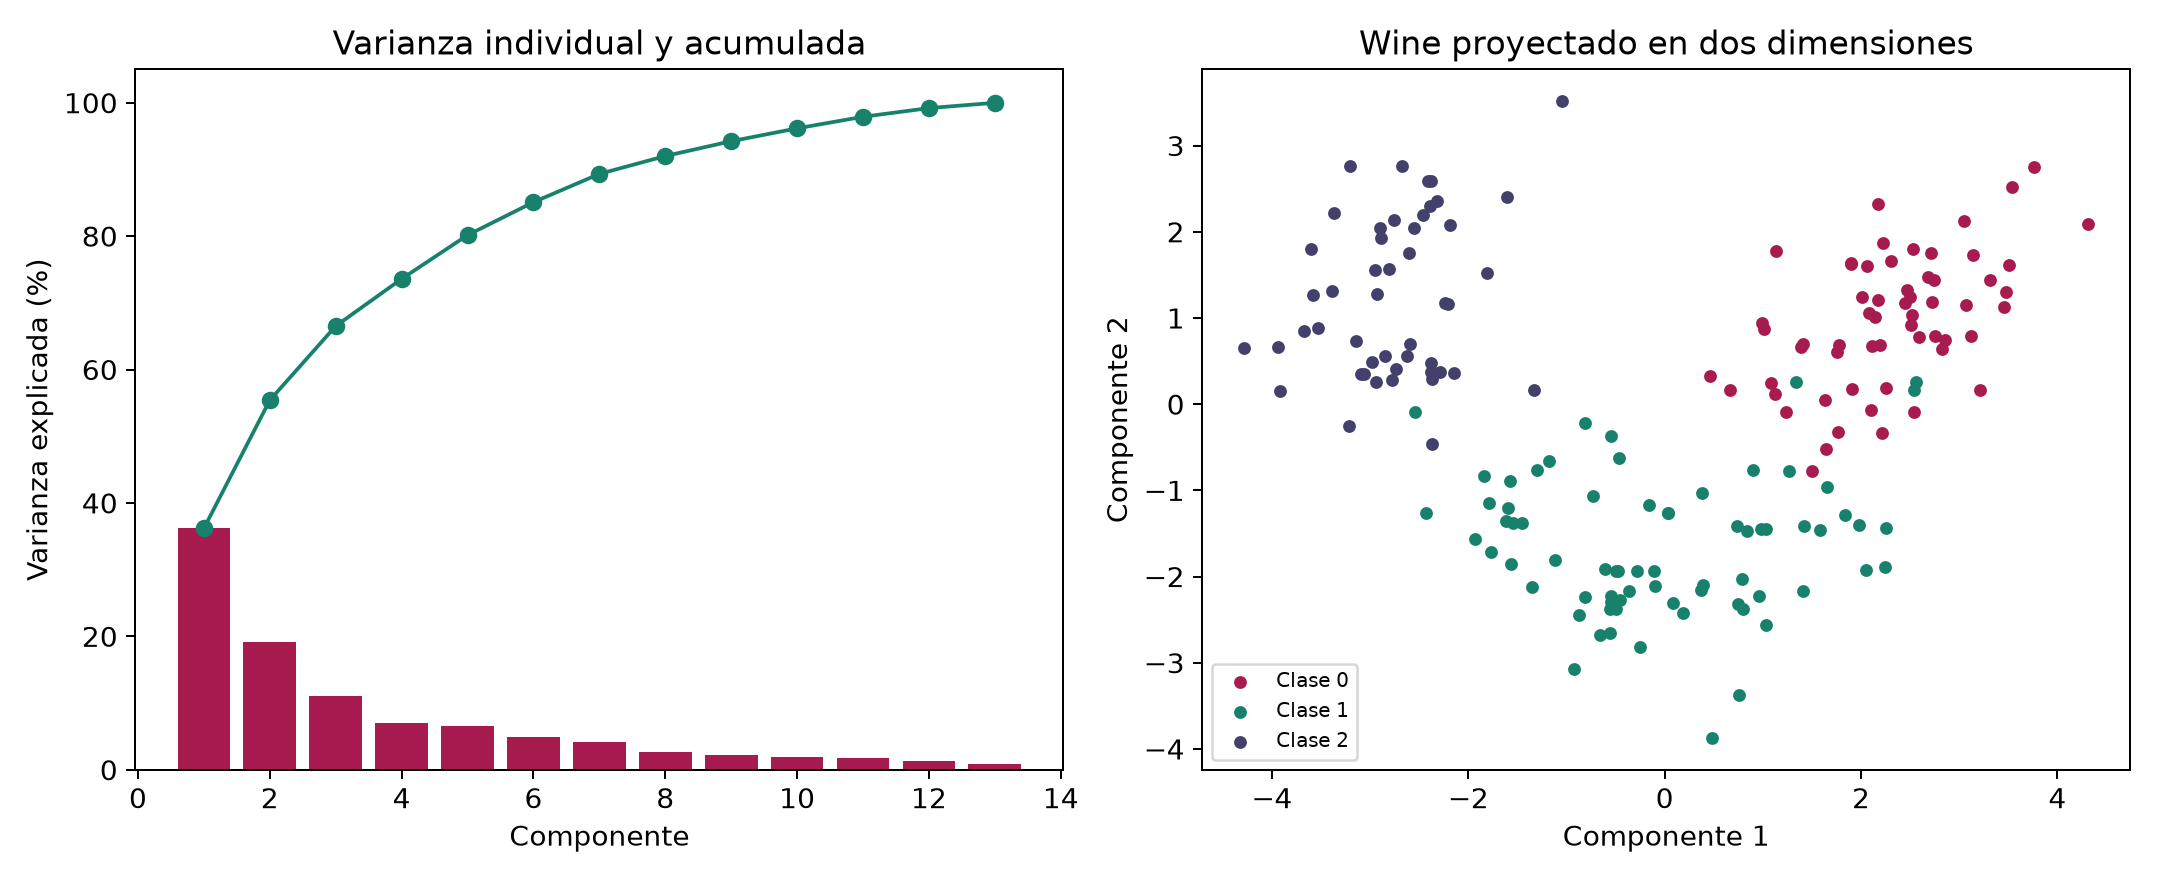

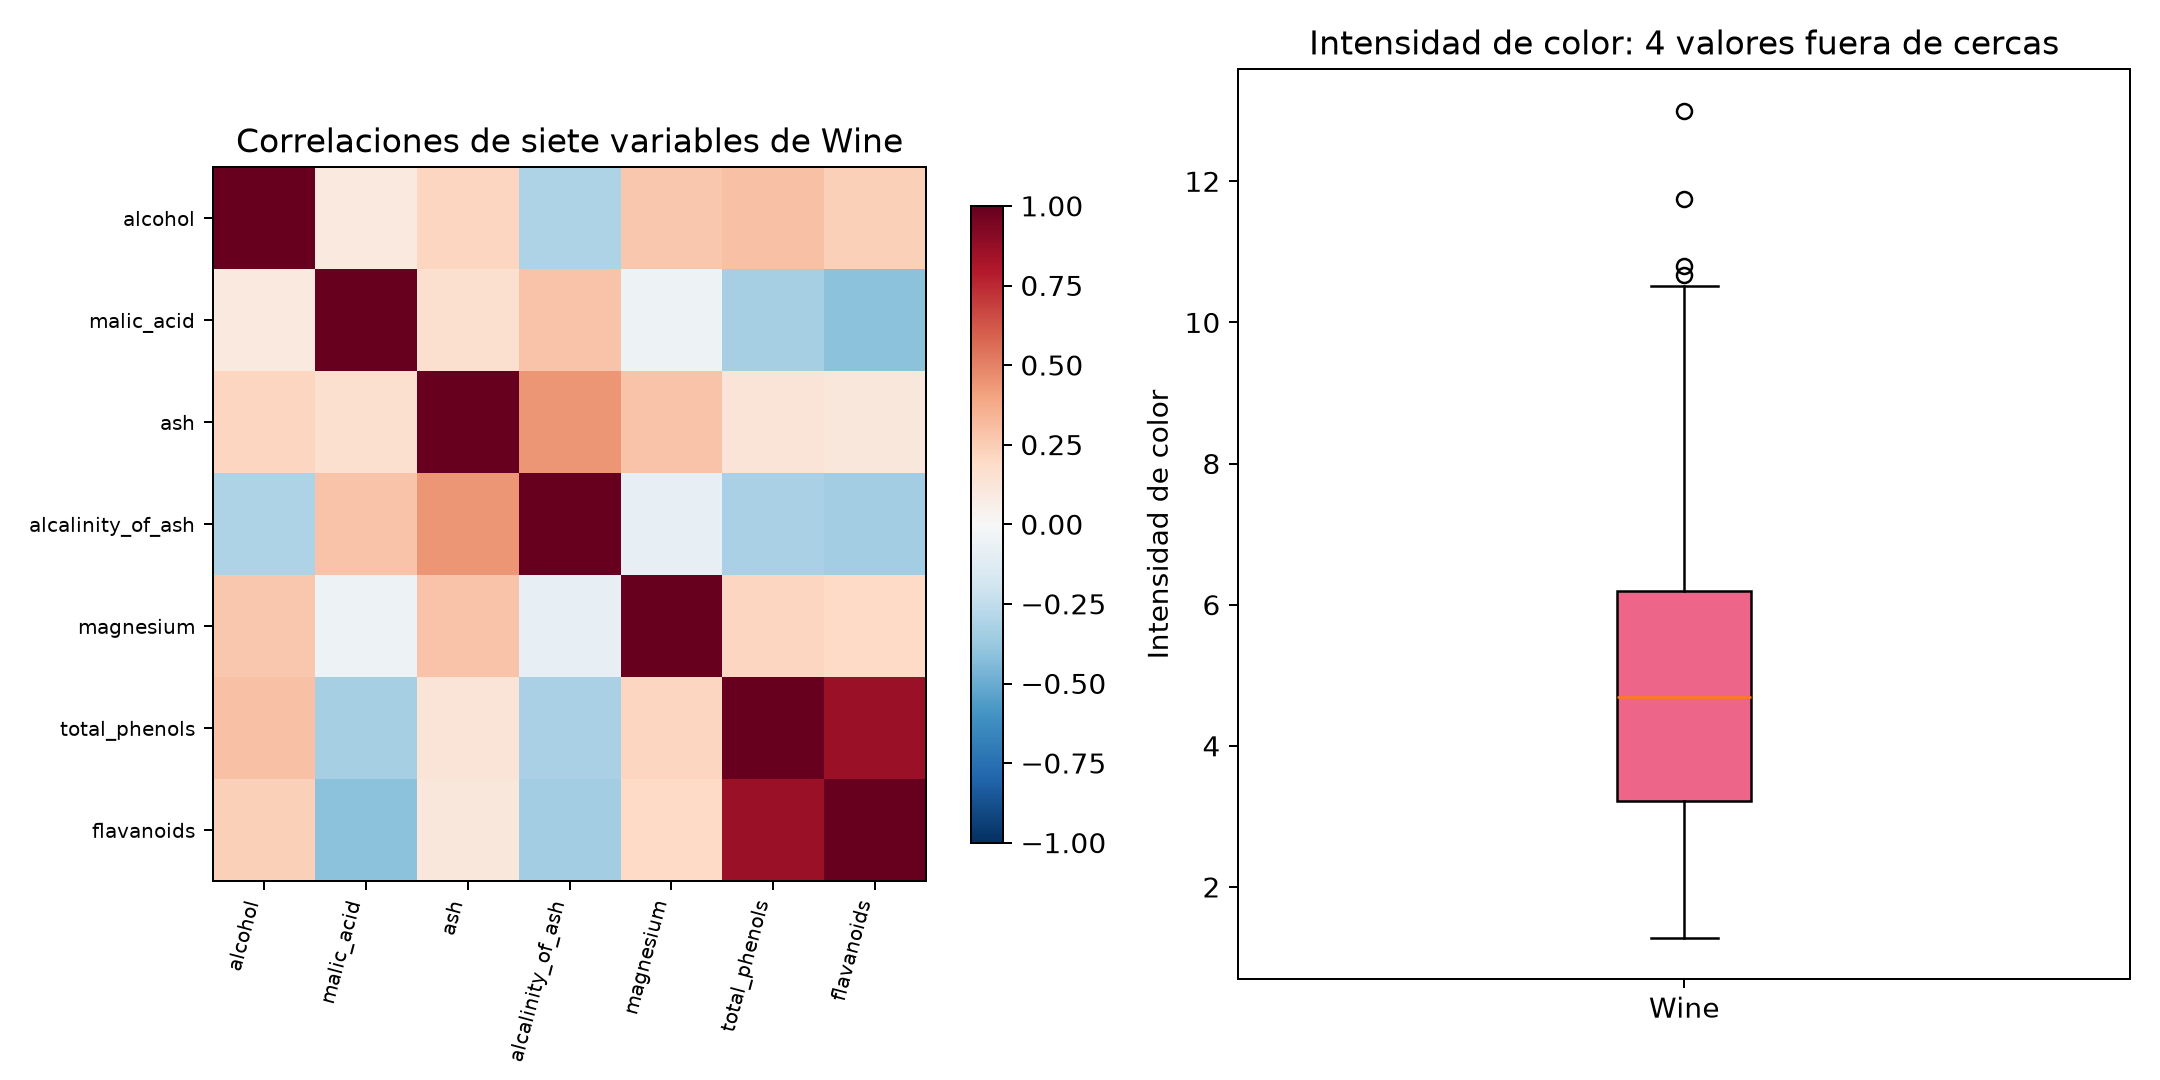

In [1]:
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, load_wine, load_digits
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
BASE = Path.cwd()
OUT = BASE / "Figuras"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "figure.dpi": 160})
colores = ["#a71b50", "#18816c", "#43406b", "#ed6589"]
def save(fig, n):
    fig.tight_layout()
    fig.savefig(OUT / f"figura_{n}.png", dpi=180)
    plt.close(fig)
# Figura 1. Datos sintéticos sin etiquetas y agrupamiento
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.1))
ax[0].scatter(*X.T, c="#999999", s=16)
ax[0].set_title("Datos sintéticos sin etiquetas")
for k in range(4):
    ax[1].scatter(*X[km.labels_ == k].T, s=16, color=colores[k], label=f"Grupo {k}")
ax[1].scatter(*km.cluster_centers_.T, marker="X", c="black", s=90, label="Centroides")
ax[1].set_title("K-Means con cuatro grupos")
for a in ax: a.set(xlabel="Variable 1", ylabel="Variable 2")
ax[1].legend(fontsize=8)
save(fig, 1)
# Figura 2. Inercia sobre el mismo conjunto
ks = range(1, 9)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]
fig, ax = plt.subplots(figsize=(8, 5.25))
ax.plot(list(ks), inercias, "o-", color=colores[0])
ax.axvline(4, linestyle="--", color=colores[1], label="Cuatro centros en el generador")
ax.set(xlabel="Número de grupos", ylabel="Inercia", title="Método del codo con datos sintéticos")
ax.legend(fontsize=9)
save(fig, 2)
# Figura 3. Wine, etiquetas usadas únicamente para colorear
wine = load_wine()
W = StandardScaler().fit_transform(wine.data)
pca = PCA().fit(W)
Z = pca.transform(W)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.9))
ax[0].bar(range(1, 14), 100*pca.explained_variance_ratio_, color=colores[0])
ax[0].plot(range(1, 14), 100*np.cumsum(pca.explained_variance_ratio_), "o-", color=colores[1])
ax[0].set(xlabel="Componente", ylabel="Varianza explicada (%)", title="Varianza individual y acumulada")
for c in range(3): ax[1].scatter(*Z[wine.target==c,:2].T, s=17, color=colores[c], label=f"Clase {c}")
ax[1].set(xlabel="Componente 1", ylabel="Componente 2", title="Wine proyectado en dos dimensiones")
ax[1].legend(fontsize=8)
save(fig, 3)
# Figura 4. Matriz de correlación y regla IQR
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
C = np.corrcoef(wine.data[:,:7], rowvar=False)
im=ax[0].imshow(C, vmin=-1, vmax=1, cmap="RdBu_r")
names=wine.feature_names[:7]
ax[0].set_xticks(range(7), names, rotation=75, ha="right", fontsize=8)
ax[0].set_yticks(range(7), names, fontsize=8)
ax[0].set_title("Correlaciones de siete variables de Wine")
fig.colorbar(im, ax=ax[0], shrink=.7)
q1,q3=np.quantile(wine.data[:,9],[.25,.75]);iqr=q3-q1
n=int(((wine.data[:,9]<q1-1.5*iqr)|(wine.data[:,9]>q3+1.5*iqr)).sum())
ax[1].boxplot(wine.data[:,9], patch_artist=True, boxprops={"facecolor":colores[3]})
ax[1].set(title=f"Intensidad de color: {n} valores fuera de cercas", ylabel="Intensidad de color")
ax[1].set_xticks([1],["Wine"])
save(fig, 4)
print("Wine: varianza acumulada en 2 componentes", round(float(pca.explained_variance_ratio_[:2].sum()),4))
